# 01 ? Devices: EDA and cleaning

Consolidated from the original `sect1` notebooks. The executable pipeline lives in `src/` (`python -m src.pipeline`); these notebooks document the exploration and the cleaning decisions it implements.


---

## Part 1 ? Preliminary EDA

# Preliminary Exploratory Data Analysis

Auto-generated overview of a CSV dataset. Drop your file in `data/raw/` and run all cells.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline
print("Libraries loaded correctly")

Libraries loaded correctly


## 1. Data Loading

Detects and loads the CSVs found in `data/raw/`.

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("devices")
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")


Loading: devices-1681209661.csv


Shape: 118,249 rows x 15 columns


In [3]:
df.head(10)

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
0,1,NaN,NaN,IVD Other,NaN,NaN,Cell-Dyn Emerald Cleanser,NaN,NaN,NaN,tur-cell-dyn-emerald-cleanser,TUR,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,Class IIB,NaN,NaN,"TECNIS Monofocal 1-piece, TECNIS 1-Piece IOL w...",NaN,NaN,NaN,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,TUR,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
2,3,NaN,NaN,Class IIA,NaN,NaN,Centurion FMS Package for Centurion Vision System,NaN,NaN,NaN,tur-centurion-fms-package-for-centurion-vision...,TUR,3,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
3,4,NaN,NaN,Class IIB,NaN,NaN,Focusforce intraocular foldable lenses,NaN,NaN,NaN,tur-focusforce-intraocular-foldable-lenses,TUR,4,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
4,5,NaN,NaN,IVD Other,NaN,NaN,Cholesterol HDL Direct,NaN,NaN,NaN,tur-cholesterol-hdl-direct,TUR,5,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
5,6,NaN,NaN,IVD Other,NaN,NaN,Blood Glucose Test Strip,NaN,NaN,NaN,tur-blood-glucose-test-strip,TUR,6,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
6,7,NaN,NaN,Class IIA,NaN,NaN,Super Arrow-Flex(R) Percutaneous Sheath Introd...,NaN,NaN,NaN,tur-super-arrow-flex-r-percutaneous-sheath-int...,TUR,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
7,8,NaN,NaN,Class III,NaN,NaN,Catheter introducer,NaN,NaN,NaN,tur-catheter-introducer,TUR,7,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
8,9,NaN,NaN,Class IIA,NaN,NaN,22g Bi-Manual Aspiration Pull Handle 0.38mm Port,NaN,NaN,NaN,tur-22g-bi-manual-aspiration-pull-handle-0-38m...,TUR,8,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
9,10,NaN,NaN,Class III,NaN,NaN,Spinocath,NaN,NaN,NaN,tur-spinocath,TUR,9,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


## 2. Column Overview

Data types, non-null counts, and memory usage.

In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118249 entries, 0 to 118248
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   id                    118249 non-null  int64 
 1   classification        35601 non-null   object
 2   code                  36218 non-null   object
 3   description           89606 non-null   object
 4   distributed_to        33626 non-null   object
 5   implanted             34898 non-null   object
 6   name                  118218 non-null  object
 7   number                63800 non-null   object
 8   quantity_in_commerce  31929 non-null   object
 9   risk_class            32948 non-null   object
 10  slug                  118249 non-null  object
 11  country               118248 non-null  object
 12  manufacturer_id       118249 non-null  int64 
 13  created_at            118249 non-null  object
 14  updated_at            118249 non-null  object
dtypes: int64(2), obje

In [5]:
dtype_counts = df.dtypes.value_counts()
print("Column type distribution:")
for dtype, count in dtype_counts.items():
    print(f"  {dtype.name}: {count} columns")

Column type distribution:
  object: 13 columns
  int64: 2 columns


## 3. Missing Values Analysis

In [6]:
print(f"{df.isna().sum().sum()}")

587398


In [7]:
# Per-column nulls
missing_cols = pd.DataFrame({
    "Missing": df.isna().sum(),
    "%": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing", ascending=False)

missing_cols = missing_cols[missing_cols["Missing"] > 0]
if missing_cols.empty:
    print("No missing values found.")
else:
    display(missing_cols)
    print(f"\nTotal missing values: {df.isna().sum().sum()}")

,Missing,%
quantity_in_commerce,86320,73.00
risk_class,85301,72.14
distributed_to,84623,71.56
implanted,83351,70.49
classification,82648,69.89
code,82031,69.37
number,54449,46.05
description,28643,24.22
name,31,0.03
country,1,0.00



Total missing values: 587398


In [8]:
# Per-row null distribution
nulls_per_row = df.isna().sum(axis=1)

print("Rows with nulls:")
for threshold in [1, 2, 5, 10, 20, 50]:
    count = (nulls_per_row >= threshold).sum()
    print(f"  ≥{threshold:>3} nulls: {count:>6,} rows ({count / len(df) * 100:>5.1f}%)")

print(f"\nNulls per row — distribution:")
dist = nulls_per_row.value_counts().sort_index()
display(dist.head(20).to_frame("# rows"))

Rows with nulls:
  ≥  1 nulls: 87,693 rows ( 74.2%)
  ≥  2 nulls: 85,323 rows ( 72.2%)
  ≥  5 nulls: 84,633 rows ( 71.6%)
  ≥ 10 nulls:      1 rows (  0.0%)
  ≥ 20 nulls:      0 rows (  0.0%)
  ≥ 50 nulls:      0 rows (  0.0%)

Nulls per row — distribution:


,# rows
0,30556
1,2370
2,98
3,186
4,406
5,732
6,28535
7,35155
8,20205
9,5


In [9]:
# Column drop recommendations (>40% nulls)
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "Null %": null_pct.round(2),
    "Recommendation": null_pct.apply(
        lambda p: "DROP (>40%)" if p > 40 else "KEEP"
    )
}).sort_values("Null %", ascending=False)

to_drop = rec_df[rec_df["Recommendation"] == "DROP (>40%)"]
if not to_drop.empty:
    print("=" * 55)
    print(f"  {len(to_drop)} column(s) with >40% nulls — recommended for removal")
    print("=" * 55)
    display(to_drop)
else:
    print("No columns exceed 40% nulls — none recommended for removal.")

  7 column(s) with >40% nulls — recommended for removal


,Null %,Recommendation
quantity_in_commerce,73.00,DROP (>40%)
risk_class,72.14,DROP (>40%)
distributed_to,71.56,DROP (>40%)
implanted,70.49,DROP (>40%)
classification,69.89,DROP (>40%)
code,69.37,DROP (>40%)
number,46.05,DROP (>40%)


## 4. Numerical Columns – Descriptive Statistics

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")

Numerical columns (2): ['id', 'manufacturer_id']
Categorical / text columns (13): ['classification', 'code', 'description', 'distributed_to', 'implanted', 'name', 'number', 'quantity_in_commerce', 'risk_class', 'slug', 'country', 'created_at', 'updated_at']


In [11]:
if num_cols:
    display(df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
id,118249.0,59125.000000,34135.690328,1.0,1183.48,5913.4,29563.0,59125.0,88687.0,112336.6,117066.52,118249.0
manufacturer_id,118249.0,15022.948321,9117.177777,1.0,614.48,2110.0,6097.0,14880.0,24087.0,30245.6,31095.52,31827.0


## 5. Categorical Columns – Value Counts

In [12]:
for col in cat_cols[:10]:
    vc = df[col].value_counts(dropna=False).head(15)
    print(f"\n--- {col} ({vc.sum():,} non-null / {df[col].nunique():,} unique) ---")
    print(vc.to_string())


--- classification (117,757 non-null / 16 unique) ---
classification
NaN                                                   82648
Cardiovascular Devices                                 5481
Orthopedic Devices                                     5353
General Hospital and Personal Use Devices              4245
General and Plastic Surgery Devices                    4160
Radiology Devices                                      3744
Clinical Chemistry and Clinical Toxicology Devices     2589
Anesthesiology Devices                                 2265
Gastroenterology-Urology Devices                       2080
Immunology and Microbiology Devices                    1149
Neurological Devices                                   1080
Hematology and Pathology Devices                       1004
Dental Devices                                          827
Ophthalmic Devices                                      631
Physical Medicine Devices                               501

--- code (88,135 non-null / 3


--- name (1,845 non-null / 93,077 unique) ---
name
Device Recall  Customed                                                         332
Device Recall  P.F.C.                                                           197
Transpac IV Monitoring Kit                                                      165
Medtronic                                                                       148
Device Recall  MAXIMIS Pedicle Screw Spinal Fixation System                     141
Device Recall  Regard                                                           140
King Systems Universal Flex2 Breathing Circuit                                  116
Device Recall  EndoVive 3s Low Profile Balloon Kits                             104
Device Recall  American Surgical                                                 83
Device Recall  Zimmer                                                            81
Device Recall  Portex                                                            80
Device Recall  Innova Se


--- number (56,258 non-null / 59,652 unique) ---
number
NaN                               54449
Model Catalog:  (Lot serial: )      476
see letter                          150
All lot numbers                     135
all                                 129
All lots                            121
see FSN | see FSN                   113
see letter | see letter             112
All serial numbers                   98
All lots.                            94
see FSN                              90
all serial numbers                   87
All lot codes                        73
All                                  72
Model: , Affected:                   59

--- quantity_in_commerce (88,369 non-null / 15,212 unique) ---
quantity_in_commerce
NaN                                       86320
1                                           239
1 unit                                      196
180,573 units total                         183
2                                           159
10                


--- slug (15 non-null / 118,249 unique) ---
slug
tur-cell-dyn-emerald-cleanser                                                                     1
tur-tecnis-monofocal-1-piece-tecnis-1-piece-iol-with-the-tecnis-itec-preloaded-delivery-system    1
tur-centurion-fms-package-for-centurion-vision-system                                             1
tur-focusforce-intraocular-foldable-lenses                                                        1
tur-cholesterol-hdl-direct                                                                        1
tur-blood-glucose-test-strip                                                                      1
tur-super-arrow-flex-r-percutaneous-sheath-introducer-set                                         1
tur-catheter-introducer                                                                           1
tur-22g-bi-manual-aspiration-pull-handle-0-38mm-port                                              1
tur-spinocath                                     

## 6. Outlier Detection (IQR method)

In [13]:
if num_cols:
    outlier_data = []
    for col in num_cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)][col].dropna()
        if len(outliers) > 0:
            outlier_data.append({
                "Column": col,
                "Outliers": len(outliers),
                "%": round(len(outliers) / df[col].notna().sum() * 100, 2),
                "Lower bound": round(lower, 2),
                "Upper bound": round(upper, 2)
            })
    if outlier_data:
        outlier_df = pd.DataFrame(outlier_data).sort_values("Outliers", ascending=False)
        display(outlier_df)
    else:
        print("No outliers detected via IQR.")

No outliers detected via IQR.


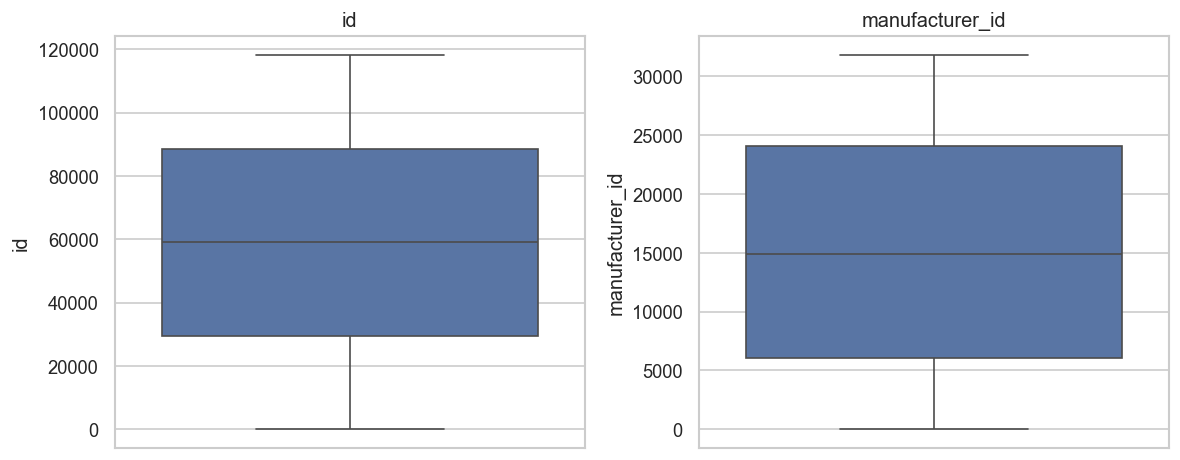

In [14]:
if num_cols:
    n_cols = min(6, len(num_cols))
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 4))
    if n_cols == 1:
        axes = [axes]
    for ax, col in zip(axes, num_cols[:n_cols]):
        sns.boxplot(y=df[col], ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

## 7. Correlation Analysis

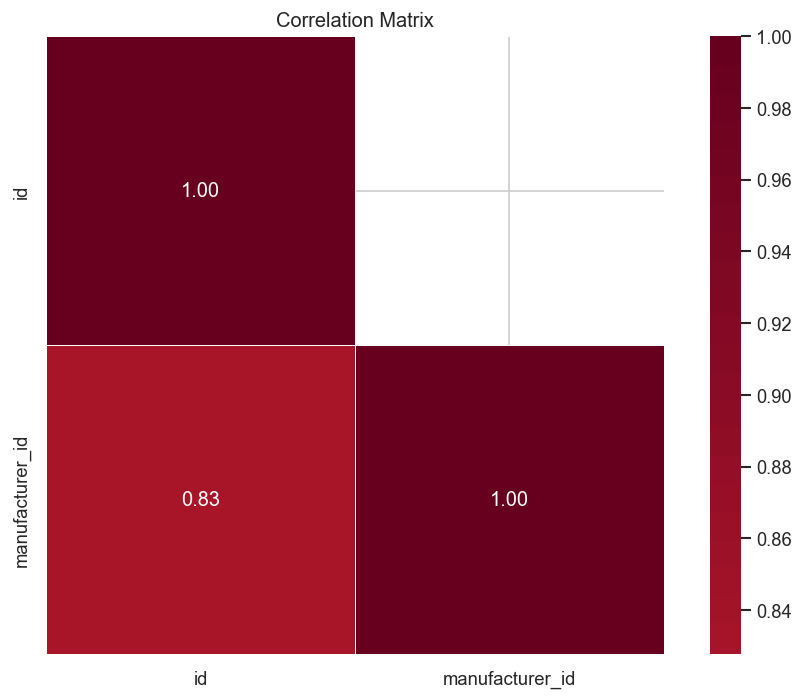

Top 10 strongest correlations:
  id  –  manufacturer_id: +0.8278


In [15]:
if len(num_cols) >= 2:
    corr = df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 20,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[
        corr_unstacked.index.get_level_values(0) !=
        corr_unstacked.index.get_level_values(1)
    ]
    top_corr = corr_unstacked.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (col1, col2), val in top_corr.items():
        print(f"  {col1}  –  {col2}: {corr.loc[col1, col2]:+.4f}")

## 8. Distribution of Numerical Columns

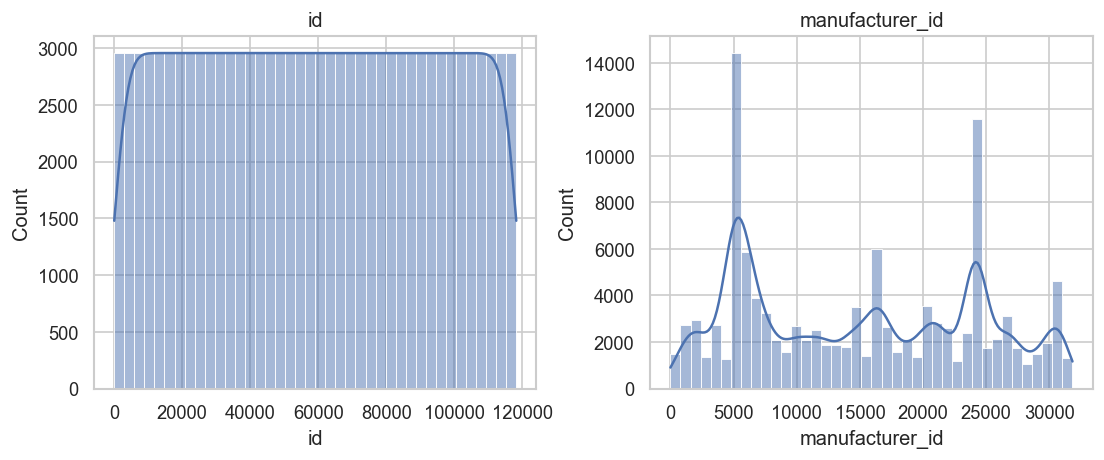

In [16]:
if num_cols:
    n_hist = min(9, len(num_cols))
    n_rows = (n_hist + 2) // 3
    fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
    axes = axes.flatten()
    for ax, col in zip(axes, num_cols[:n_hist]):
        sns.histplot(df[col].dropna(), kde=True, bins=40, ax=ax)
        ax.set_title(col)
    for ax in axes[n_hist:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

## 9. Summary

In [17]:
rows_with_nulls = (df.isna().sum(axis=1) >= 1).sum()
cols_to_drop = (df.isna().mean() * 100 > 40).sum()

print("=" * 60)
print("PRELIMINARY EDA SUMMARY")
print("=" * 60)

print(f"\nDataset: {file_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Missing cells: {df.isna().sum().sum():,} / {df.size:,} ({df.isna().sum().sum() / df.size * 100:.2f}%)")
print(f"Rows with ≥1 null: {rows_with_nulls:,} ({rows_with_nulls / len(df) * 100:.1f}%)")
print(f"Columns with >40% nulls (recommended for removal): {cols_to_drop}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

PRELIMINARY EDA SUMMARY

Dataset: devices-1681209661.csv
Dimensions: 118,249 rows x 15 columns
Missing cells: 587,398 / 1,773,735 (33.12%)
Rows with ≥1 null: 87,693 (74.2%)
Columns with >40% nulls (recommended for removal): 7
Duplicate rows: 0
Numerical columns: 2
Categorical columns: 13


Memory usage: 127.90 MB


---

## Part 2 ? Formal EDA

# 01. Formal Exploratory Data Analysis

Structured deep-dive into the dataset. Builds on the preliminary EDA with richer diagnostics.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline
print("Libraries loaded correctly")

Libraries loaded correctly


In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("devices")
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

print("Working with Devices CSV")


Loading: devices-1681209661.csv


Shape: 118,249 rows x 15 columns
Working with Devices CSV


## 1. Schema Audit

Complete column-by-column diagnostic: type, nulls, cardinality, memory.

In [3]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "cardinality": df.nunique(dropna=False),
    "memory_kb": (df.memory_usage(deep=True) / 1024).round(1)
})
display(schema)
print(f"Total memory: {schema['memory_kb'].sum():,.1f} KB")

,dtype,non_null,null_pct,cardinality,memory_kb
Index,NaN,NaN,NaN,NaN,0.1
classification,object,35601.0,69.89,17.0,5255.5
code,object,36218.0,69.37,3024.0,4539.2
country,object,118248.0,0.00,47.0,6004.8
created_at,object,118249.0,0.00,8627.0,8314.4
description,object,89606.0,24.22,60799.0,17674.5
distributed_to,object,33626.0,71.56,12028.0,10307.5
id,int64,118249.0,0.00,118249.0,923.8
implanted,object,34898.0,70.49,3.0,4351.7
manufacturer_id,int64,118249.0,0.00,31716.0,923.8


Total memory: 130,968.3 KB


In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical: {len(num_cols)}  |  Categorical: {len(cat_cols)}")

Numerical: 2  |  Categorical: 13


In [5]:
df.select_dtypes(include=[np.number]).columns.tolist()


['id', 'manufacturer_id']

In [6]:
print((df['id']==df['manufacturer_id']).sum()/df.shape[0])

5.919711794602914e-05


Looks like manufacturer_id will be a foreing key to another csv in the study case, I will be checking that in the EDA of the other CSVs.

## 2. Missing Values - Full Diagnosis

In [7]:
missing_cols = schema[schema["null_pct"] > 0][["null_pct"]].sort_values("null_pct", ascending=False)
if not missing_cols.empty:
    display(missing_cols)
else:
    print("No missing values.")

,null_pct
quantity_in_commerce,73.00
risk_class,72.14
distributed_to,71.56
implanted,70.49
classification,69.89
code,69.37
number,46.05
description,24.22
name,0.03


Rows with >=X nulls:
  >=  1: 87,693 ( 74.2%)
  >=  2: 85,323 ( 72.2%)
  >=  5: 84,633 ( 71.6%)
  >= 10:      1 (  0.0%)
  >= 20:      0 (  0.0%)
  >= 50:      0 (  0.0%)


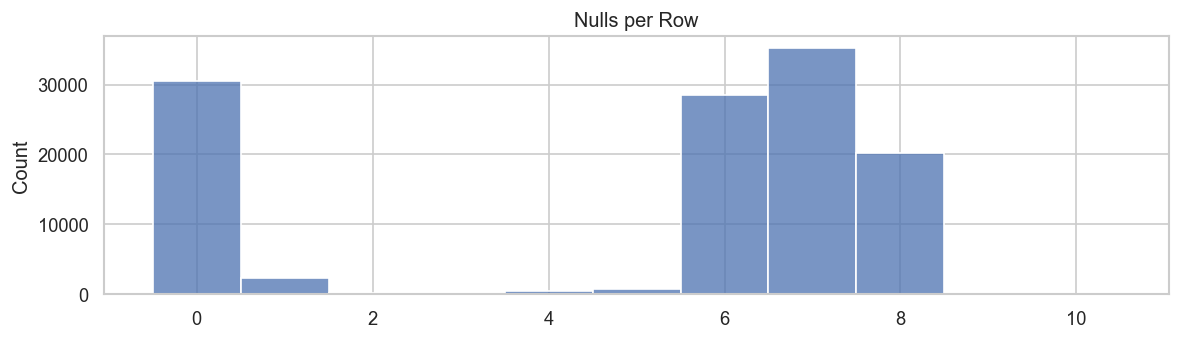

In [8]:
nulls_per_row = df.isna().sum(axis=1)
print("Rows with >=X nulls:")
for t in [1, 2, 5, 10, 20, 50]:
    n = (nulls_per_row >= t).sum()
    print(f"  >={t:>3}: {n:>6,} ({n/len(df)*100:>5.1f}%)")

if nulls_per_row.max() > 0:
    plt.figure(figsize=(10, 3))
    sns.histplot(nulls_per_row, bins=min(50, nulls_per_row.max()+1), discrete=True)
    plt.title("Nulls per Row")
    plt.tight_layout()
    plt.show()

In [9]:
null_pct = df.isna().mean() * 100 #Esto calcula porciento, remember True=1
null_pct.sort_values(ascending=False)

quantity_in_commerce    72.998503
risk_class              72.136762
distributed_to          71.563396
implanted               70.487700
classification          69.893191
code                    69.371411
number                  46.046055
description             24.222615
name                     0.026216
country                  0.000846
id                       0.000000
slug                     0.000000
manufacturer_id          0.000000
created_at               0.000000
updated_at               0.000000
dtype: float64

Puedo hacer un drop de las columnas que tienen un % mayor a 40%. No sirve la cantidad de nulls para el análisis.  
| Columna | Porciento de nulls (%) |
| :--- | :--- |
| quantity_in_commerce |    72.99850 |  
| risk_class |             72.136762 |  
| distributed_to |         71.563396 |  
| implanted |              70.487700 |  
| classification |         69.893191 |  
| code |                   69.371411 |  
| number |                 46.046055 |  

In [10]:
df.shape[0]*0.33

39022.17

In [11]:
df.head(2)

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
0,1,NaN,NaN,IVD Other,NaN,NaN,Cell-Dyn Emerald Cleanser,NaN,NaN,NaN,tur-cell-dyn-emerald-cleanser,TUR,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,Class IIB,NaN,NaN,"TECNIS Monofocal 1-piece, TECNIS 1-Piece IOL w...",NaN,NaN,NaN,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,TUR,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


In [12]:
print((df['created_at']==df['updated_at']).sum()/df.shape[0])

0.9930739372003146


El valor anterior me dice que la columna "created_at" y "updated_at" son iguales el 99.31% de los casos. Para este análisis haré el drop de la columna "updated_at".

## 3. Numerical Analysis

In [13]:
df['manufacturer_id'].unique()

array([    1,     2,     3, ..., 31825, 31826, 31827], shape=(31716,))

In [14]:
df['manufacturer_id'].duplicated().sum()

np.int64(86533)

In [15]:
type(num_cols)

list

In [16]:
num_cols[1]

'manufacturer_id'

In [17]:
if num_cols:
    stats = df[num_cols[1]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    
    stats["skew"] = df[num_cols[1]].skew().round(3)
    stats["kurtosis"] = df[num_cols[1]].kurtosis().round(3)
    display(stats)

count       118249.000000
mean         15022.948321
std           9117.177777
min              1.000000
1%             614.480000
5%            2110.000000
25%           6097.000000
50%          14880.000000
75%          24087.000000
95%          30245.600000
99%          31095.520000
max          31827.000000
skew             0.138000
kurtosis        -1.319000
Name: manufacturer_id, dtype: float64

Esta columna numérica me servirá para hacer análisis junto con el resto de datos.

## 4. Categorical Analysis

In [18]:
df['country']

0         TUR
1         TUR
2         TUR
3         TUR
4         TUR
         ... 
118244    MYS
118245    MYS
118246    MYS
118247    MYS
118248    MYS
Name: country, Length: 118249, dtype: object

In [19]:
if cat_cols:
    cat_summary = pd.DataFrame({
        "unique": df[cat_cols].nunique().sort_values(ascending=False),
        "top_val": [df[c].value_counts(dropna=False).index[0] if df[c].nunique() > 0 else None for c in cat_cols],
        "top_pct": [round(df[c].value_counts(dropna=False).iloc[0] / len(df) * 100, 1) for c in cat_cols]
    })
    display(cat_summary)

,unique,top_val,top_pct
slug,118249,NaN,69.9
name,93077,NaN,69.4
description,60798,NaN,24.2
number,59652,NaN,71.6
quantity_in_commerce,15212,NaN,70.5
distributed_to,12027,Device Recall Customed,0.3
updated_at,8629,NaN,46.0
created_at,8627,NaN,73.0
code,3023,NaN,72.1
country,46,tur-cell-dyn-emerald-cleanser,0.0


In [20]:
len(df['implanted'].unique())

3

Las columnas tienen un valor adicional al que dice la columna unique anterior, esto por el conteo literal que hace la celda anterior.

In [21]:
df['risk_class'].unique()

array([nan, 'II', '2', '1', '3', 'Not Classified', 'Unclassified', 'HDE'],
      dtype=object)

In [22]:
df['risk_class'].isna().sum()

np.int64(85301)

In [23]:
df.shape

(118249, 15)

In [24]:
df['country']

0         TUR
1         TUR
2         TUR
3         TUR
4         TUR
         ... 
118244    MYS
118245    MYS
118246    MYS
118247    MYS
118248    MYS
Name: country, Length: 118249, dtype: object

In [25]:
test = df.copy()

In [26]:
test['country']

0         TUR
1         TUR
2         TUR
3         TUR
4         TUR
         ... 
118244    MYS
118245    MYS
118246    MYS
118247    MYS
118248    MYS
Name: country, Length: 118249, dtype: object

In [27]:
test['country'].unique()

array(['TUR', 'COL', 'MEX', 'AUT', 'JPN', 'PRT', 'HRV', 'NZL', 'PER',
       'ITA', 'RUS', 'FRA', 'BLR', 'USA', 'SRB', 'PAN', 'ESP', 'SAU',
       'SLV', 'IND', 'GRC', 'NLD', 'DEU', nan, 'SVN', 'HKG', 'CZE', 'SGP',
       'SWE', 'CUB', 'PHL', 'GBR', 'FIN', 'CHE', 'BRA', 'POL', 'CAN',
       'KOR', 'LTU', 'IRL', 'DNK', 'TUN', 'BEL', 'AND', 'AUS', 'LBN',
       'MYS'], dtype=object)

When nulls are cleaned I´m gonna stay with just one value un country column, so I will drop it.

In [28]:
test = test.dropna()

In [29]:
test.head()

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
12529,12530,General Hospital and Personal Use Devices,LBI,"Replacement LED PCB Kit, part number 001840, o...",worldwide,NO,Device Recall Natus neoBLUE 2 Phototherapy sy...,All distributed Natus neoBLUE 2 systems with L...,1907 total (1413 in US and 494 international),2,usa-general-hospital-and-personal-use-devices-...,USA,4827,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12530,12531,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 13/80 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,Catalog: 04541472001 and lots: 5053291 and 507...,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12531,12532,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 13/110 10 + 10 pieces || P...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,Catalog: 04541456001 and lot: 5052067,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12532,12533,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 17/60 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Catalog: 04541502001 and lots: 5044353, 504667...","Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12533,12534,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 17/80 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Catalog: 04541529001 and lots: 5044354, 505130...","Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC


In [30]:
test['slug'].unique()[:5]

array(['usa-general-hospital-and-personal-use-devices-device-recall-natus-neoblue-2-phototherapy-system',
       'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set',
       'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set-c5d309c9',
       'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set-81a910d7',
       'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set-830a10dc'],
      dtype=object)

I´m gonna keep the slug for foward analysis. This column may have relation with another CSV, otherwise it will be droped.

In [31]:
test.groupby('implanted')['implanted'].count()

implanted
NO     23984
YES     6572
Name: implanted, dtype: int64

In [32]:
test.shape

(30556, 15)

I can make a drop of the rows, no de las columnas.

In [33]:
test['country']

12529     USA
12530     USA
12531     USA
12532     USA
12533     USA
         ... 
104291    USA
104292    USA
104293    USA
104294    USA
104295    USA
Name: country, Length: 30556, dtype: object

In [34]:
df=test.copy()

## 5. Correlation Analysis

I need to analyze the dependency relations.

In [35]:
cross_tab = pd.crosstab(df['risk_class'], df['implanted'])
print(cross_tab)

implanted          NO   YES
risk_class                 
1                5331     0
2               17831  5127
3                 591  1392
HDE                 4    11
Not Classified     31     2
Unclassified      196    40


In [36]:
desclasificados = df.loc[(test['risk_class'] == 'Not Classified') | (test['risk_class'] == 'Unclassified')]


In [37]:
desclasificados.shape

(269, 15)

In [38]:
desclasificados.loc[desclasificados['risk_class'] == 'Not Classified', 'risk_class'] = 'Unclassified'


In [39]:
desclasificados['risk_class'].unique()

array(['Unclassified'], dtype=object)

In [40]:
desclasificados['risk_class'].count()

np.int64(269)

In [41]:
desclasificados.loc[(desclasificados['risk_class'] == 'Not Classified')]

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at


In [42]:
test.loc[test['risk_class'] == 'Not Classified', 'risk_class'] = 'Unclassified'

In [43]:
test.columns

Index(['id', 'classification', 'code', 'description', 'distributed_to',
       'implanted', 'name', 'number', 'quantity_in_commerce', 'risk_class',
       'slug', 'country', 'manufacturer_id', 'created_at', 'updated_at'],
      dtype='object')

In [44]:
cross_tab = pd.crosstab(test['risk_class'], test['implanted'])
print(cross_tab)

implanted        NO   YES
risk_class               
1              5331     0
2             17831  5127
3               591  1392
HDE               4    11
Unclassified    227    42


In [45]:
df['code'].unique()

array(['LBI', 'FPA', 'MEC', ..., 'HGC', 'KTW', 'IDP'],
      shape=(2042,), dtype=object)

In [46]:
cross_tab = pd.crosstab(df['risk_class'], df['implanted'])
print(cross_tab)

implanted          NO   YES
risk_class                 
1                5331     0
2               17831  5127
3                 591  1392
HDE                 4    11
Not Classified     31     2
Unclassified      196    40


In [47]:
df['number'].head(3)

12529    All distributed Natus neoBLUE 2 systems with L...
12530    Catalog: 04541472001 and lots: 5053291 and 507...
12531                Catalog: 04541456001 and lot: 5052067
Name: number, dtype: object

I won´t use the information in the 'number' column.

## 6. Outlier Analysis

Como el dataframe tiene dos columnas numéricas solamente que son id y una posible clave foránea entonces el análsis de outliers se enfocará en detectar patrones de escrituras y errores en las otras columnas.

In [48]:
print(df['classification'].dtype)

object


In [49]:
(~df['classification'].str.isdigit()).sum()

np.int64(30556)

In [50]:
df['country']

12529     USA
12530     USA
12531     USA
12532     USA
12533     USA
         ... 
104291    USA
104292    USA
104293    USA
104294    USA
104295    USA
Name: country, Length: 30556, dtype: object

In [51]:
(df['classification'].str.isalpha())

12529     False
12530     False
12531     False
12532     False
12533     False
          ...  
104291    False
104292    False
104293    False
104294    False
104295    False
Name: classification, Length: 30556, dtype: bool

In [52]:
s1 = pd.Series(["one", "one1", "1", "", "Arizo y yo"])
s1.str.isalpha()

0     True
1    False
2    False
3    False
4    False
dtype: bool

In [53]:
def isAlphaOnly(text):
    return text.replace(' ','').replace('-','').replace(',','').isalpha()

In [54]:
result = pd.DataFrame()

for c in cat_cols:
    is_alpha_and_not_empty = df[c].apply(isAlphaOnly) & ~df[c].astype(str).str.isdigit() & (df[c] != '')
    result[c] = is_alpha_and_not_empty.values

print(result.sum())

classification          30556
code                    30556
description               514
distributed_to           5536
implanted               30556
name                    18647
number                   1163
quantity_in_commerce      122
risk_class                284
slug                    13304
country                 30556
created_at                  0
updated_at                  0
dtype: int64


In [55]:
df[cat_cols].sample(n=3, random_state=2) 

,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,created_at,updated_at
21685,Cardiovascular Devices,MKJ,Powerheart AED G3 Automated External Defibrill...,"Throughout the United States, Canada and Europe.",NO,Device Recall Powerheart AED G3,Model no. 9300P serial numbers: 900290 thru 9...,193,3,usa-cardiovascular-devices-device-recall-power...,USA,2022-08-04 08:39:00 UTC,2022-08-04 08:39:00 UTC
99022,Hematology and Pathology Devices,GKZ,Coulter MAXM Hematology Analyzer and MAXM Hema...,"Worldwide Distribution -- US, Algeria, Andorra...",NO,Device Recall Coulter MAXM Hematology Analyze...,All serial numbers.,4288 units total,2,usa-hematology-and-pathology-devices-device-re...,USA,2022-08-04 10:15:41 UTC,2022-08-04 10:15:41 UTC
100656,Cardiovascular Devices,DQY,Multi-Lumen Central Venous Catheterization || Kit,"US Distribution including the states of MD, NC...",NO,Arrow MultiLumen Central Venous Catheterization,Catolog No - AK-12703 lot number RF3039028,65,2,usa-cardiovascular-devices-arrow-multilumen-ce...,USA,2022-08-04 10:18:35 UTC,2022-08-04 10:18:35 UTC


Creo que number no nos servirá para el análisis.

In [56]:
df['country']

12529     USA
12530     USA
12531     USA
12532     USA
12533     USA
         ... 
104291    USA
104292    USA
104293    USA
104294    USA
104295    USA
Name: country, Length: 30556, dtype: object

## 7. Summary & Recommendations

## EDA at the moment Conclusions

### 1. Data Overview
- Original shape: **118,249 rows × 15 columns**
- After removing rows with nulls: **30,556 rows × 15 columns**
- 74.2% of rows had at least one null value

### 2. Columns to be Removed
- **`updated_at`**: Dropped because it was ~99.3% identical to `created_at`
- **`number`**: Discarded for analysis — contains free-form text (serial numbers, catalog numbers), no clean categorical/numerical value

### 3. Columns with High Null Rate (>40%)
Seven columns had over 40% missing values: `quantity_in_commerce` (73%), `risk_class` (72.1%), `distributed_to` (71.6%), `implanted` (70.5%), `classification` (69.9%), `code` (69.4%), `number` (46.0%). Rather than dropping these columns, rows with nulls were removed to preserve potentially useful information.

### 4. Numerical Columns
Only 2 numerical columns: `id` (unique row identifier) and `manufacturer_id` (posibly foreign key to manufacturers table). No true numerical features for traditional outlier detection — analysis focused on text pattern anomalies instead.

### 5. Categorical Insights
- **`risk_class`**: I must clean by unifying `"Not Classified"` → `"Unclassified"`. Cross-tab with `implanted` shows **risk class 1 devices are never implanted**, while classes 2, 3, and HDE appear in both implanted and non-implanted records.
- **`classification`** and **`code`**: High cardinality (16 and ~3,000 values respectively) but are clean text fields suitable for grouping.
- **`slug`**: Retained as a potential join key with other CSVs.
- **`number`**: Retained as a potential join key with other CSVs.
- **`country`**: 47 unique values, mostly clean.

### 6. Text Quality
- Columns `classification`, `code`, `implanted`, `country` are consistently alphabetic and clean.
- `description` and `name` contain mixed content (letters, numbers, symbols) but are informative.
- `quantity_in_commerce` and `distributed_to` contain verbose descriptions rather than structured data.

### 7. Next Steps
- Join with manufacturers CSV using `manufacturer_id` (this in powerBI)
- Further clean `risk_class` and `classification` if needed
- Decide on `slug` use based on other datasets

---

## Part 3 ? Pre-cleaning

# 02. Data Pre-Cleaning

Transforms raw data into a pre-cleaned state for downstream processing. Each step logs changes.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re


In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("devices")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
n_row0, n_col0 = df.shape
print(f"Loaded: {file_path.name}  ({n_row0:,} rows x {n_col0:,} cols)")


Loaded: devices-1681209661.csv  (118,249 rows x 15 cols)


In [3]:
print(f"Output directory: {proc_dir}")


Output directory: D:\projects\dataScienceProjects\medicalSupply\data\processed


## 1. Applying anotations of first EDA

Remove rows where nulls are present.

In [4]:
df.head(1)

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
0,1,NaN,NaN,IVD Other,NaN,NaN,Cell-Dyn Emerald Cleanser,NaN,NaN,NaN,tur-cell-dyn-emerald-cleanser,TUR,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


In [5]:
df = df.dropna()

In [6]:
df.shape

(30556, 15)

In [7]:
df.drop(columns='updated_at', inplace = True)

In [8]:
df.columns

Index(['id', 'classification', 'code', 'description', 'distributed_to',
       'implanted', 'name', 'number', 'quantity_in_commerce', 'risk_class',
       'slug', 'country', 'manufacturer_id', 'created_at'],
      dtype='object')

In [9]:
df.drop(columns='number', inplace = True)

In [10]:
df.columns

Index(['id', 'classification', 'code', 'description', 'distributed_to',
       'implanted', 'name', 'quantity_in_commerce', 'risk_class', 'slug',
       'country', 'manufacturer_id', 'created_at'],
      dtype='object')

In [11]:
df['manufacturer_id']

12529      4827
12530      4828
12531      4828
12532      4828
12533      4828
          ...  
104291     4892
104292    26448
104293     5571
104294     5645
104295     5645
Name: manufacturer_id, Length: 30556, dtype: int64

Unifying two categories in 'risk_class':

In [12]:
df.loc[df['risk_class'] == 'Not Classified', 'risk_class'] = 'Unclassified'

In [13]:
df['risk_class'].unique()

array(['2', '1', '3', 'Unclassified', 'HDE'], dtype=object)

In [14]:
df['country'].unique()

array(['USA'], dtype=object)

## 2. Drop constant and duplicate columns

In [15]:
# Constant columns (single value)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
df.drop(columns=const_cols, inplace=True)
print(f"Dropped {len(const_cols)} constant column(s): {const_cols}")

Dropped 1 constant column(s): ['country']


In [16]:
# Duplicate columns (identical values)
dup_cols = []
seen = {}
for col in df.columns:
    key = tuple(df[col].astype(str).fillna("__NULL__"))
    if key in seen:
        dup_cols.append(col)
    else:
        seen[key] = col
df.drop(columns=dup_cols, inplace=True)
print(f"Dropped {len(dup_cols)} duplicate column(s): {dup_cols}")

Dropped 0 duplicate column(s): []


## 3. Standardize column names

Convert to snake_case: lowercase, spaces/hyphens to underscores, strip special chars.

In [17]:
def clean_col_name(name: str) -> str:
    name = name.strip().lower()
    name = re.sub(r"[^\w\s]", "", name)
    name = re.sub(r"[\s\-]+", "_", name)
    name = re.sub(r"_+", "_", name).strip("_")
    return name

old_names = list(df.columns)
new_names = [clean_col_name(c) for c in old_names]
rename_map = {o: n for o, n in zip(old_names, new_names) if o != n}
df.rename(columns=rename_map, inplace=True)
print(f"Renamed {len(rename_map)} column(s)")
if rename_map:
    for old, new in rename_map.items():
        print(f"  {old:30s} -> {new}")

Renamed 0 column(s)


In [18]:
df.columns

Index(['id', 'classification', 'code', 'description', 'distributed_to',
       'implanted', 'name', 'quantity_in_commerce', 'risk_class', 'slug',
       'manufacturer_id', 'created_at'],
      dtype='object')

Columns are normalized

## 4. String cleaning

Strip leading/trailing whitespace from all object columns.

In [19]:
str_cols = df.select_dtypes(include=["object", "string"]).columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip().replace("nan", None)
print(f"Cleaned {len(str_cols)} string column(s)")

Cleaned 10 string column(s)


In [20]:
# Optimize low-cardinality categoricals
cat_cols = df.select_dtypes(include=["object", "string"]).columns
cat_opt = []
for col in cat_cols:
    if df[col].nunique() / len(df) < 0.05:
        df[col] = df[col].astype("category")
        cat_opt.append(col)
print(f"Optimized {len(cat_opt)} column(s) to category: {cat_opt}")

Optimized 3 column(s) to category: ['classification', 'implanted', 'risk_class']


## 6. Deduplicate rows

In [21]:
n_before = len(df)
df.drop_duplicates(inplace=True)
n_dupes = n_before - len(df)
print(f"Removed {n_dupes:,} duplicate row(s) ({n_dupes/n_before*100:.2f}%)")

Removed 0 duplicate row(s) (0.00%)

## 7. Save pre-cleaned data

In [22]:
df.to_csv(f"{proc_dir}/devicesProcessed.csv", index=False, encoding='utf-8')

## 8. Pre-cleaning Report

In [23]:
date_cols = []  # el notebook de devices no incluye un paso de conversion de fechas
n_row1, n_col1 = df.shape
print("=" * 55)
print("  PRE-CLEANING REPORT")
print("=" * 55)
print(f"  Original shape:           {n_row0:>8,} rows x {n_col0:,} cols")
print(f"  Final shape:              {n_row1:>8,} rows x {n_col1:,} cols")
print(f"  Rows removed (dupes):     {n_dupes:>8,}")
print(f"  Columns dropped:          {n_col0 - n_col1:>8}")
print(f"    - Constant:             {len(const_cols):>8}")
print(f"    - Duplicate:            {len(dup_cols):>8}")
print(f"  Columns renamed:          {len(rename_map):>8}")
print(f"  Dates parsed:             {len(date_cols):>8}")
print(f"  Optimized to category:    {len(cat_opt):>8}")
print(f"  Remaining missing:        {df.isna().sum().sum():>8,}")

  PRE-CLEANING REPORT
  Original shape:            118,249 rows x 15 cols
  Final shape:                30,556 rows x 12 cols
  Rows removed (dupes):            0
  Columns dropped:                 3
    - Constant:                    1
    - Duplicate:                   0
  Columns renamed:                 0
  Dates parsed:                    0
  Optimized to category:           3
  Remaining missing:               0
